## Assignment no 15

## East-West Airlines Customer Segmentation – Complete Clustering Analysis

Step 1: Import required libraries

In [4]:
# Data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Clustering algorithms
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

# Evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# PCA for visualization
from sklearn.decomposition import PCA

# DBSCAN parameter selection
from sklearn.neighbors import NearestNeighbors

# Dendrogram
from scipy.cluster.hierarchy import dendrogram, linkage

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_style("whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [47]:
# Check whether the correct customer dataset is loaded

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

# Remove duplicate records
df = df.drop_duplicates()

# Separate ID from customer features
customer_ids = df["ID#"].copy()

X_df = df.drop(
    columns=["ID#"]
).copy()

# Convert all features to numeric
for col in X_df.columns:
    X_df[col] = pd.to_numeric(
        X_df[col],
        errors="coerce"
    )

# Handle missing values
imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X_df),
    columns=X_df.columns,
    index=X_df.index
)

# Scale features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print("Preprocessing completed!")
print("Final feature shape:", X_scaled.shape)

Dataset Shape: (3999, 15)

Column Names:
['ID#', 'Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll', 'Award?', 'KMeans_Cluster', 'Hierarchical_Cluster', 'DBSCAN_Cluster']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   ID#                   3999 non-null   int64
 1   Balance               3999 non-null   int64
 2   Qual_miles            3999 non-null   int64
 3   cc1_miles             3999 non-null   int64
 4   cc2_miles             3999 non-null   int64
 5   cc3_miles             3999 non-null   int64
 6   Bonus_miles           3999 non-null   int64
 7   Bonus_trans           3999 non-null   int64
 8   Flight_miles_12mo     3999 non-null   int64
 9   Flight_trans_12       3999 non-null   int64
 10  Days

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,KMeans_Cluster,Hierarchical_Cluster,DBSCAN_Cluster
0,1,28143,0,1,1,1,174,1,0,0,7000,0,4,0,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0,4,0,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0,4,0,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0,4,0,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1,0,2,0


Preprocessing completed!
Final feature shape: (3999, 14)


Step 2: Load the dataset

In [6]:
# Dataset file path
file_path = "EastWestAirlines.xlsx"

# Load the customer data sheet
df = pd.read_excel(file_path, sheet_name="data")

# Display first five rows
display(df.head())

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


Step 3: Understand the dataset

In [7]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe().T)

Dataset Shape: (3999, 12)

Column Names:
['ID#', 'Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll', 'Award?']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64

,count,mean,std,min,25%,50%,75%,max
ID#,3999.0,2014.819455,1160.764358,1.0,1010.5,2016.0,3020.5,4021.0
Balance,3999.0,73601.327582,100775.664958,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.114529,773.663804,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.059515,1.376919,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.014504,0.147650,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.012253,0.195241,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.846212,24150.967826,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.601900,9.603810,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.055764,1400.209171,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.373593,3.793172,0.0,0.0,0.0,1.0,53.0


Step 4: Data cleaning

In [8]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of Duplicate Rows:", df.duplicated().sum())

# Check column data types
print("\nData Types:")
print(df.dtypes)

Missing Values:
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

Number of Duplicate Rows: 0

Data Types:
ID#                  int64
Balance              int64
Qual_miles           int64
cc1_miles            int64
cc2_miles            int64
cc3_miles            int64
Bonus_miles          int64
Bonus_trans          int64
Flight_miles_12mo    int64
Flight_trans_12      int64
Days_since_enroll    int64
Award?               int64
dtype: object


In [9]:
# Remove duplicate records
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (3999, 12)


In [10]:
required_columns = [
    "ID#", "Balance", "Qual_miles",
    "cc1_miles", "cc2_miles", "cc3_miles",
    "Bonus_miles", "Bonus_trans",
    "Flight_miles_12mo", "Flight_trans_12",
    "Days_since_enroll", "Award?"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns not found: {missing_columns}")

print("All expected columns are available.")

All expected columns are available.


Step 5: Separate ID and clustering features

In [11]:
# Save customer IDs separately
customer_ids = df["ID#"].copy()

# Remove ID column
X = df.drop(columns=["ID#"]).copy()

# Convert feature columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

print("Features used for clustering:")
print(X.columns.tolist())

display(X.head())

Features used for clustering:
['Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll', 'Award?']


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,28143,0,1,1,1,174,1,0,0,7000,0
1,19244,0,1,1,1,215,2,0,0,6968,0
2,41354,0,1,1,1,4123,4,0,0,7034,0
3,14776,0,1,1,1,500,1,0,0,6952,0
4,97752,0,4,1,1,43300,26,2077,4,6935,1


Step 6: Handle missing values

In [12]:
# Create median imputer
imputer = SimpleImputer(strategy="median")

# Fill missing values
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Missing values after imputation:")
print(X_imputed.isnull().sum().sum())

display(X_imputed.head())

Missing values after imputation:
0


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,28143.0,0.0,1.0,1.0,1.0,174.0,1.0,0.0,0.0,7000.0,0.0
1,19244.0,0.0,1.0,1.0,1.0,215.0,2.0,0.0,0.0,6968.0,0.0
2,41354.0,0.0,1.0,1.0,1.0,4123.0,4.0,0.0,0.0,7034.0,0.0
3,14776.0,0.0,1.0,1.0,1.0,500.0,1.0,0.0,0.0,6952.0,0.0
4,97752.0,0.0,4.0,1.0,1.0,43300.0,26.0,2077.0,4.0,6935.0,1.0


Step 7: Exploratory Data Analysis (EDA)

7.1 Distribution of features using histograms

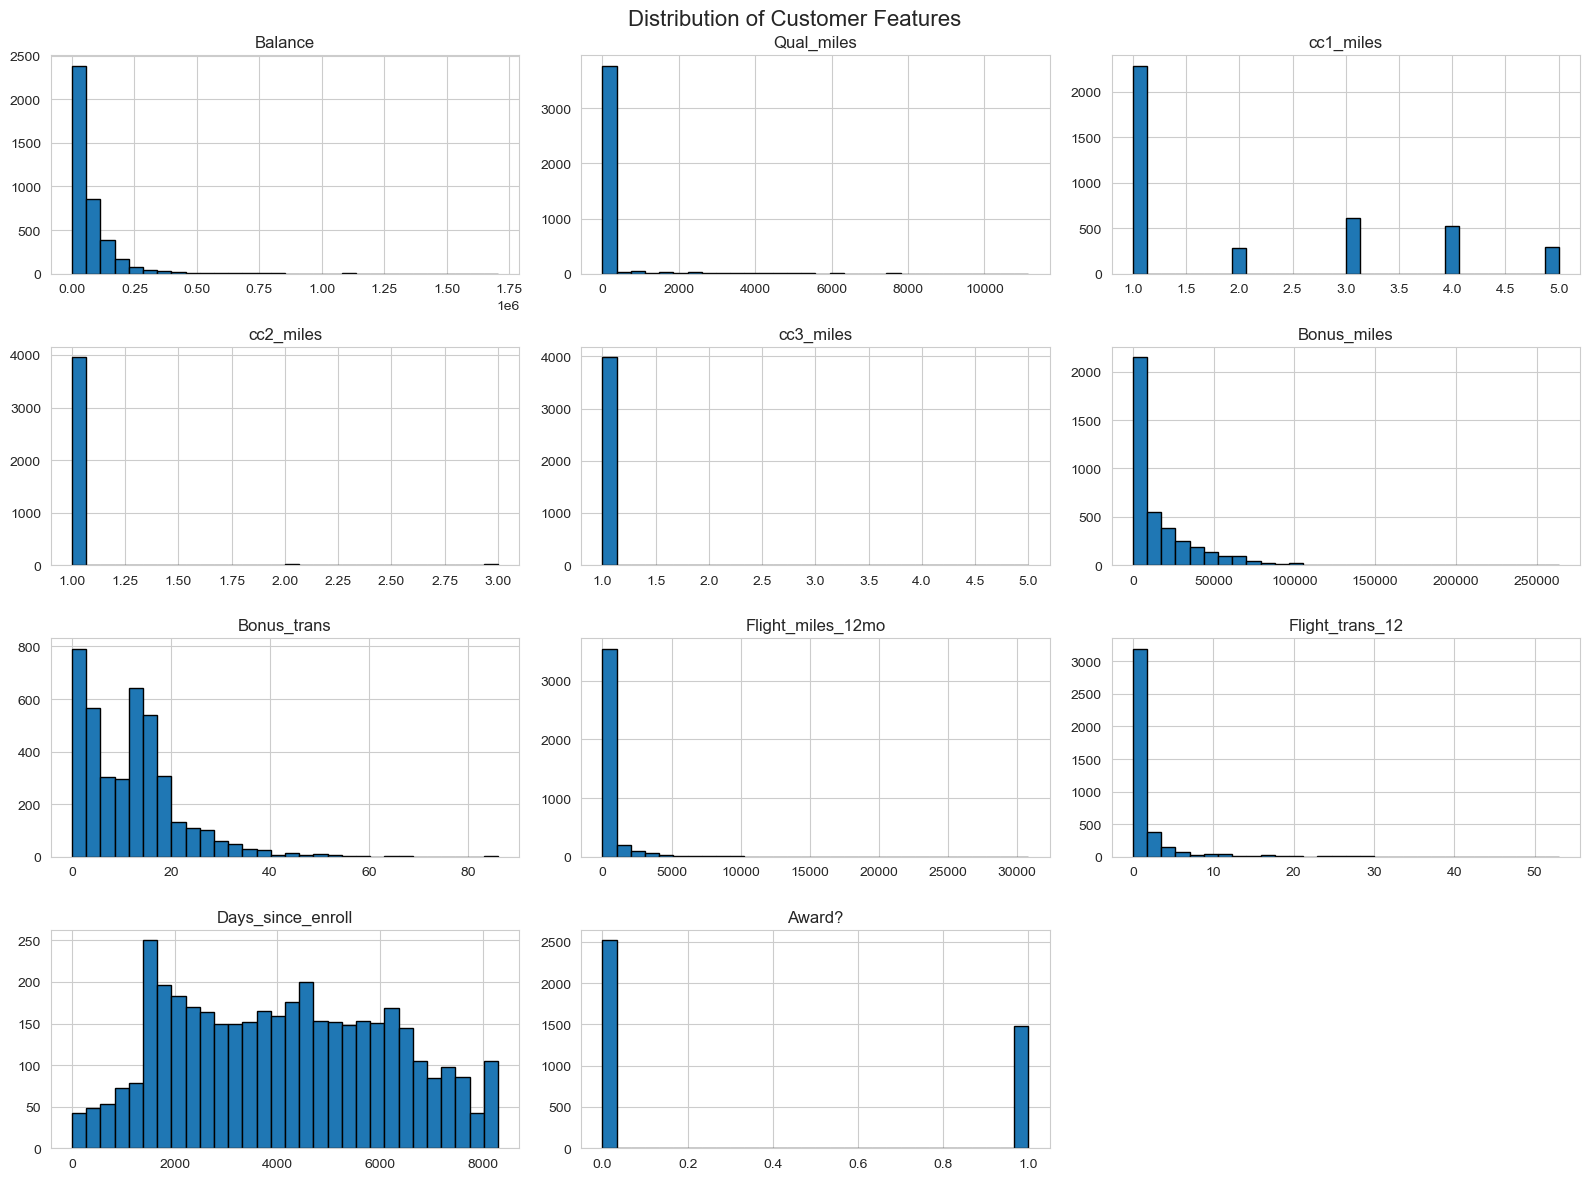

In [13]:
X_imputed.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Customer Features", fontsize=16)
plt.tight_layout()
plt.show()

7.2 Box plots to identify outliers

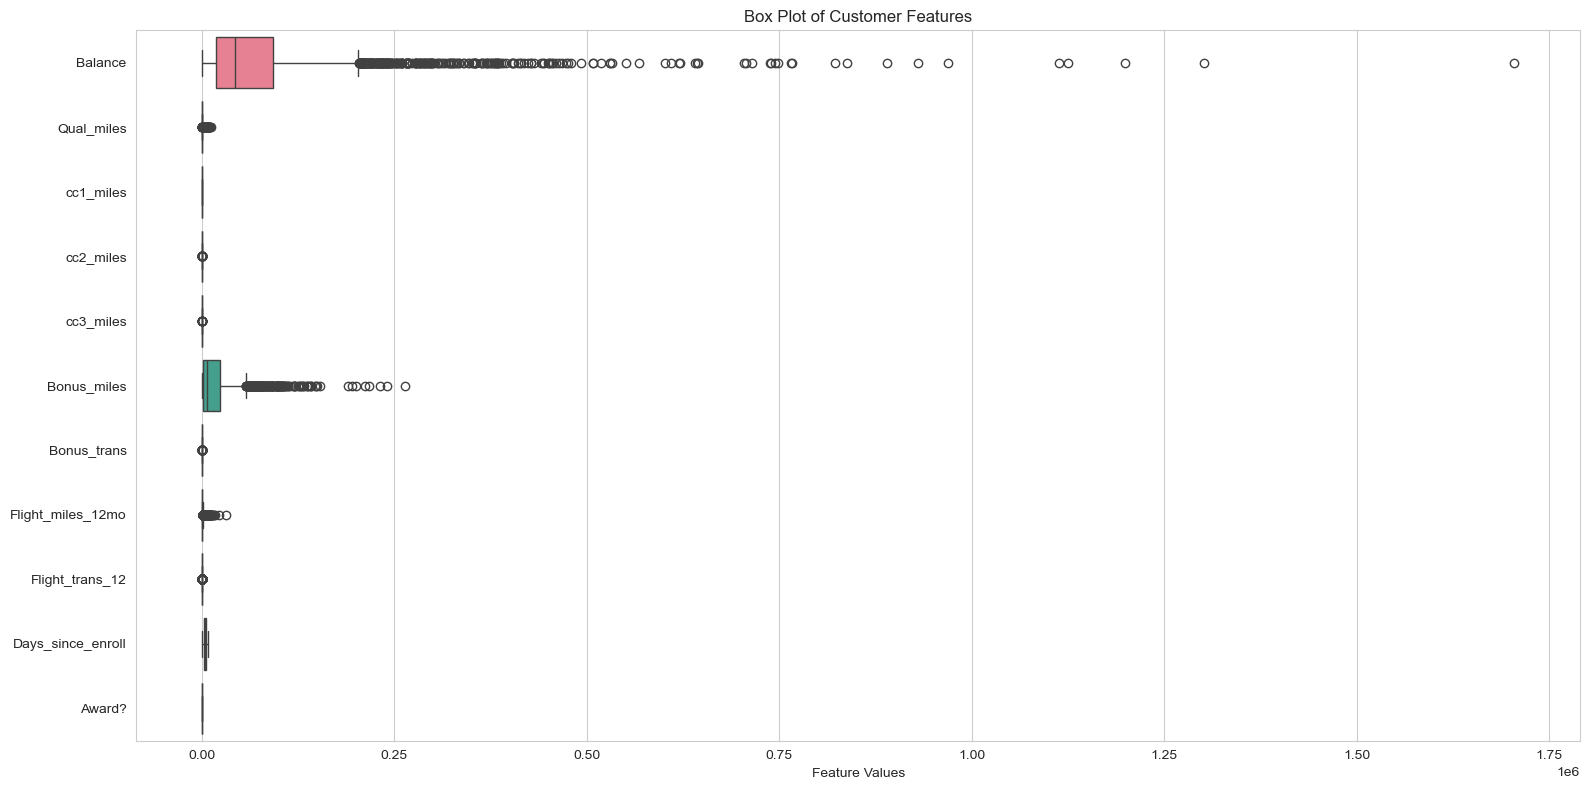

In [14]:
plt.figure(figsize=(16, 8))

sns.boxplot(data=X_imputed, orient="h")

plt.title("Box Plot of Customer Features")
plt.xlabel("Feature Values")
plt.tight_layout()
plt.show()

7.3 Correlation heatmap

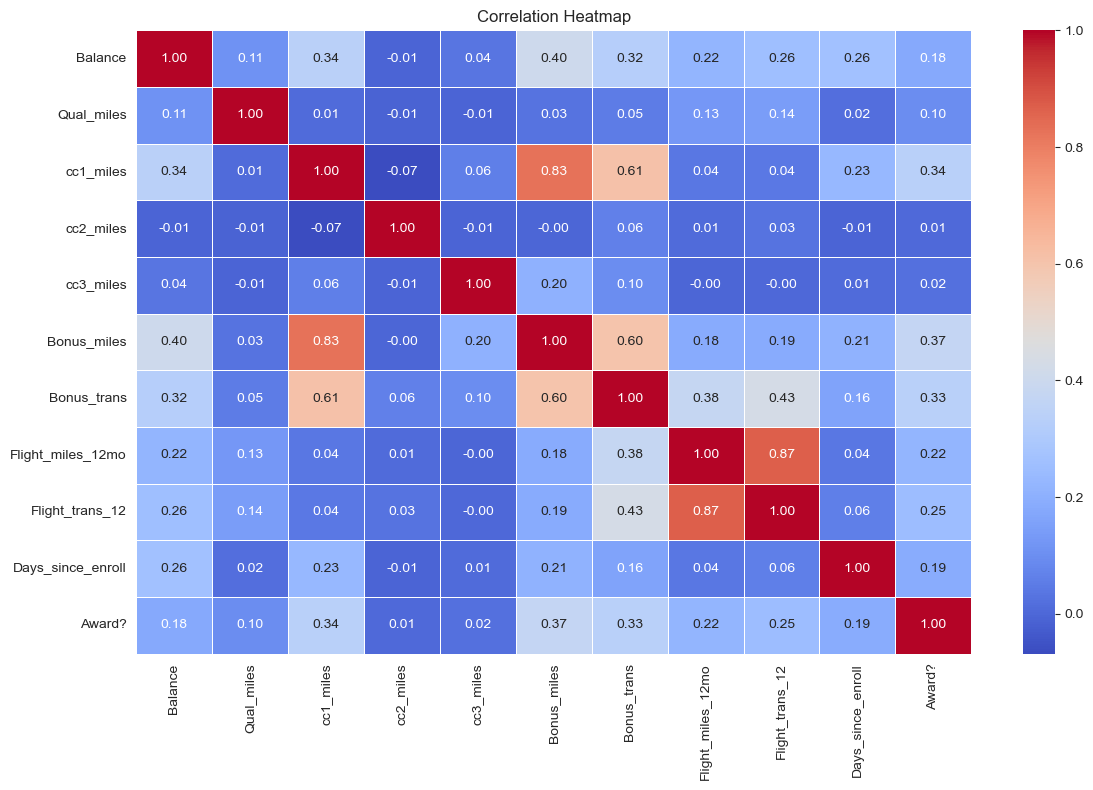

In [15]:
plt.figure(figsize=(12, 8))

correlation = X_imputed.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

7.4 Pair plot

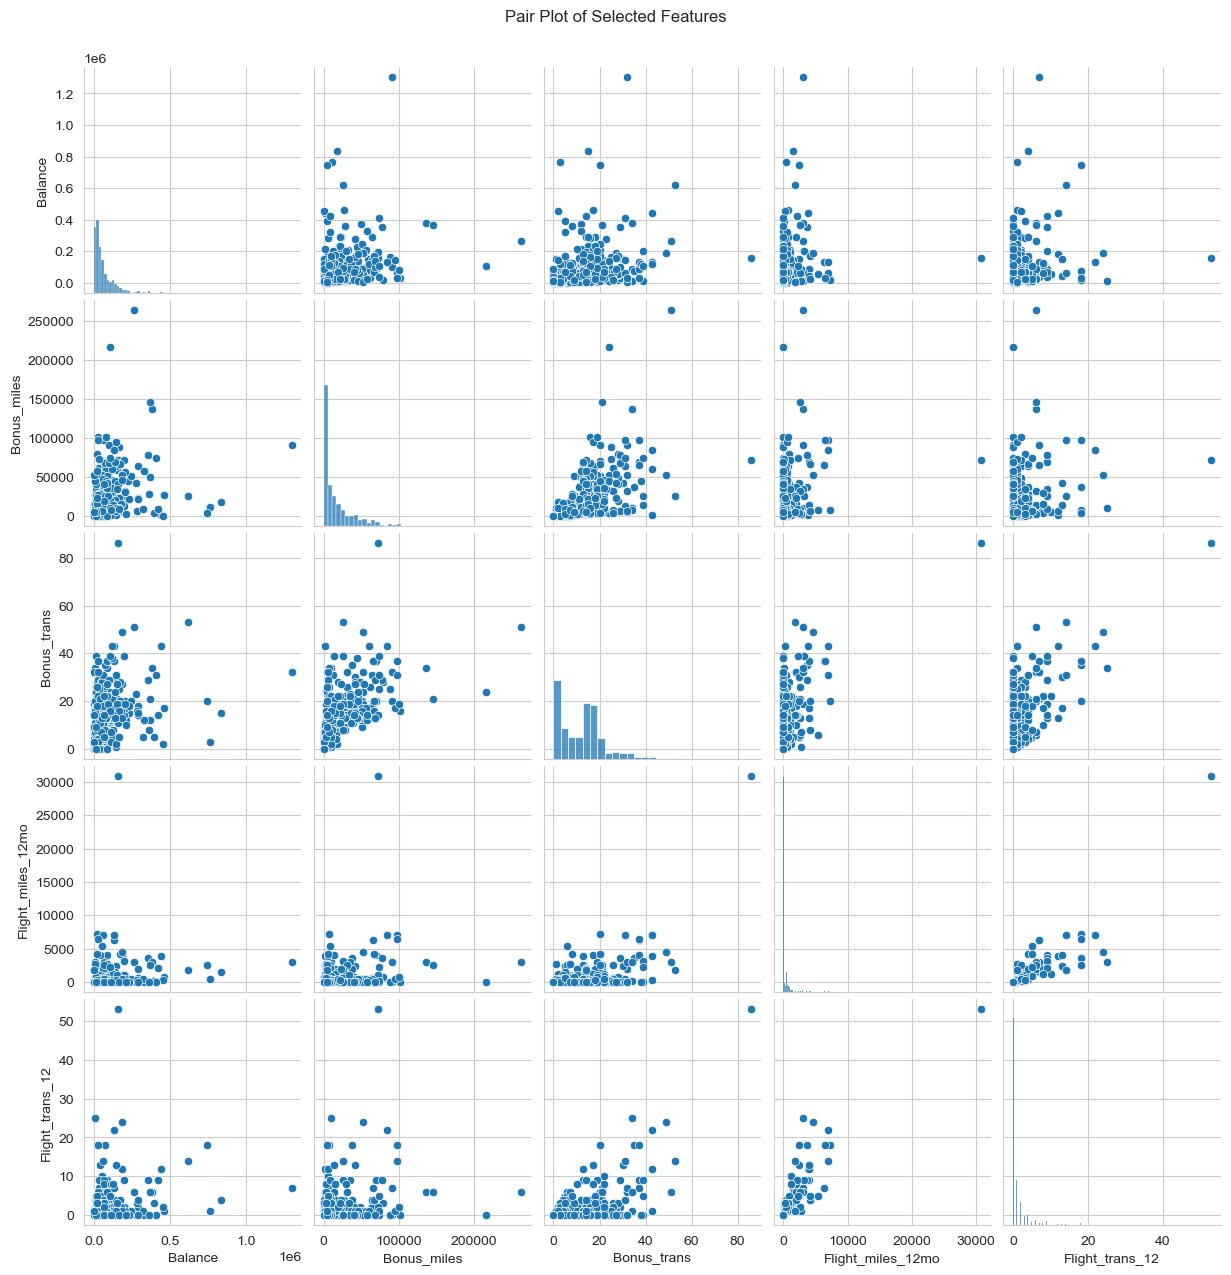

In [16]:
selected_features = [
    "Balance",
    "Bonus_miles",
    "Bonus_trans",
    "Flight_miles_12mo",
    "Flight_trans_12"
]

sns.pairplot(
    X_imputed[selected_features].sample(
        min(500, len(X_imputed)),
        random_state=42
    ),
    diag_kind="hist"
)

plt.suptitle("Pair Plot of Selected Features", y=1.02)
plt.show()

Step 8: Outlier detection using IQR

In [17]:
# Continuous features for outlier analysis
continuous_features = [
    "Balance",
    "Qual_miles",
    "Bonus_miles",
    "Bonus_trans",
    "Flight_miles_12mo",
    "Flight_trans_12",
    "Days_since_enroll"
]

# Count outliers in each feature
outlier_counts = {}

for col in continuous_features:

    Q1 = X_imputed[col].quantile(0.25)
    Q3 = X_imputed[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    count = (
        (X_imputed[col] < lower_limit) |
        (X_imputed[col] > upper_limit)
    ).sum()

    outlier_counts[col] = count

outlier_df = pd.DataFrame(
    list(outlier_counts.items()),
    columns=["Feature", "Outlier Count"]
)

display(outlier_df)

,Feature,Outlier Count
0,Balance,266
1,Qual_miles,226
2,Bonus_miles,280
3,Bonus_trans,63
4,Flight_miles_12mo,569
5,Flight_trans_12,565
6,Days_since_enroll,0


8.1 Handle outliers using IQR capping

In [18]:
# Create a copy
X_clean = X_imputed.copy()

for col in continuous_features:

    Q1 = X_clean[col].quantile(0.25)
    Q3 = X_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    X_clean[col] = X_clean[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier capping completed.")

display(X_clean.head())

Outlier capping completed.


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,28143.0,0.0,1.0,1.0,1.0,174.0,1.0,0.0,0.0,7000.0,0.0
1,19244.0,0.0,1.0,1.0,1.0,215.0,2.0,0.0,0.0,6968.0,0.0
2,41354.0,0.0,1.0,1.0,1.0,4123.0,4.0,0.0,0.0,7034.0,0.0
3,14776.0,0.0,1.0,1.0,1.0,500.0,1.0,0.0,0.0,6952.0,0.0
4,97752.0,0.0,4.0,1.0,1.0,43300.0,26.0,777.5,2.5,6935.0,1.0


Step 9: Feature scaling using StandardScaler

In [19]:
# Initialize StandardScaler
scaler = StandardScaler()

# Scale all features
X_scaled = scaler.fit_transform(X_clean)

# Convert scaled data into DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X_clean.columns,
    index=X_clean.index
)

print("Feature scaling completed.")

display(X_scaled_df.head())

Feature scaling completed.


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,-0.607258,0.0,-0.769578,-0.098242,-0.062767,-0.843091,-1.148854,-0.604313,-0.626143,1.395454,-0.766919
1,-0.758947,0.0,-0.769578,-0.098242,-0.062767,-0.840822,-1.039133,-0.604313,-0.626143,1.379957,-0.766919
2,-0.382070,0.0,-0.769578,-0.098242,-0.062767,-0.624581,-0.819689,-0.604313,-0.626143,1.411920,-0.766919
3,-0.835106,0.0,-0.769578,-0.098242,-0.062767,-0.825052,-1.148854,-0.604313,-0.626143,1.372208,-0.766919
4,0.579265,0.0,1.409471,-0.098242,-0.062767,1.543191,1.594189,2.034489,2.020176,1.363975,1.303918


Step 10: K-Means clustering

10.1 Find the optimal number of clusters using the Elbow Method

c:\Users\yashr\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\yashr\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\yashr\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\yashr\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\yashr\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

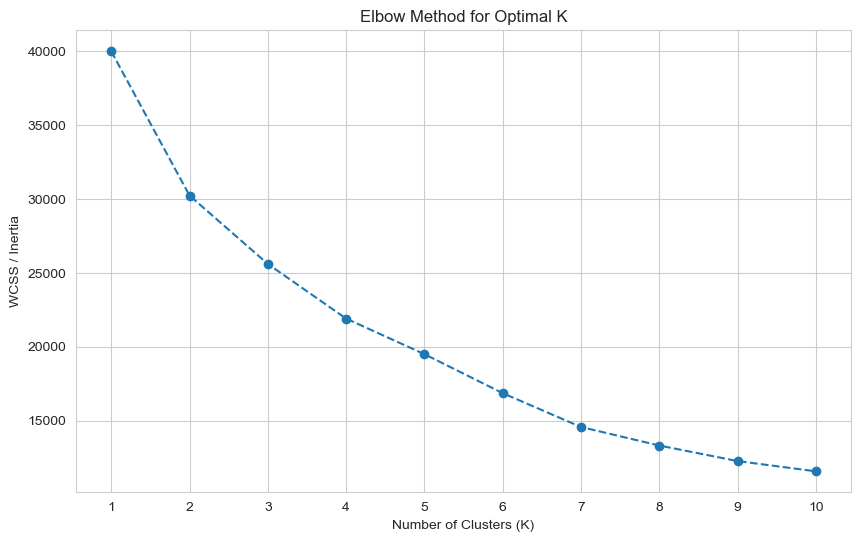

In [20]:
# Store WCSS values
wcss = []

# Test K values from 1 to 10
for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 11),
    wcss,
    marker="o",
    linestyle="--"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

10.2 Evaluate K-Means for different K values

In [21]:
kmeans_results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    kmeans_results.append({
        "K": k,
        "WCSS": model.inertia_,
        "Silhouette Score": sil,
        "Davies-Bouldin Score": db,
        "Calinski-Harabasz Score": ch
    })

kmeans_results_df = pd.DataFrame(kmeans_results)

display(kmeans_results_df.round(4))

,K,WCSS,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,2,30234.9405,0.3089,1.5258,1289.5998
1,3,25608.5280,0.2967,1.4662,1122.0552
2,4,21916.2230,0.2968,1.1695,1098.2016
3,5,19508.2795,0.2961,1.1562,1048.3280
4,6,16872.8111,0.2144,1.2126,1094.1518
5,7,14582.9378,0.2321,1.1577,1159.1766
6,8,13330.6059,0.2460,1.2049,1140.2080
7,9,12278.6652,0.2534,1.1380,1125.6235
8,10,11585.4422,0.2556,1.2190,1086.6696


10.3 Plot silhouette scores for different K values

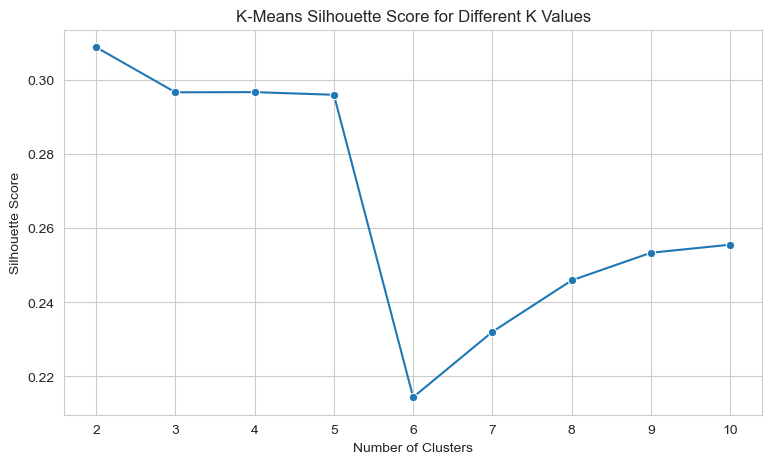

In [22]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=kmeans_results_df,
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("K-Means Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.show()

10.4 Train the final K-Means model

In [23]:
# Select number of clusters
optimal_k = 5

# Create final K-Means model
kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Generate cluster labels
kmeans_labels = kmeans_final.fit_predict(X_scaled)

# Add labels to original dataset
df["KMeans_Cluster"] = kmeans_labels

print("K-Means clustering completed.")

display(df.head())

K-Means clustering completed.


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,KMeans_Cluster
0,1,28143,0,1,1,1,174,1,0,0,7000,0,4
1,2,19244,0,1,1,1,215,2,0,0,6968,0,4
2,3,41354,0,1,1,1,4123,4,0,0,7034,0,4
3,4,14776,0,1,1,1,500,1,0,0,6952,0,4
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1,0


Step 11: Visualize K-Means clusters using PCA

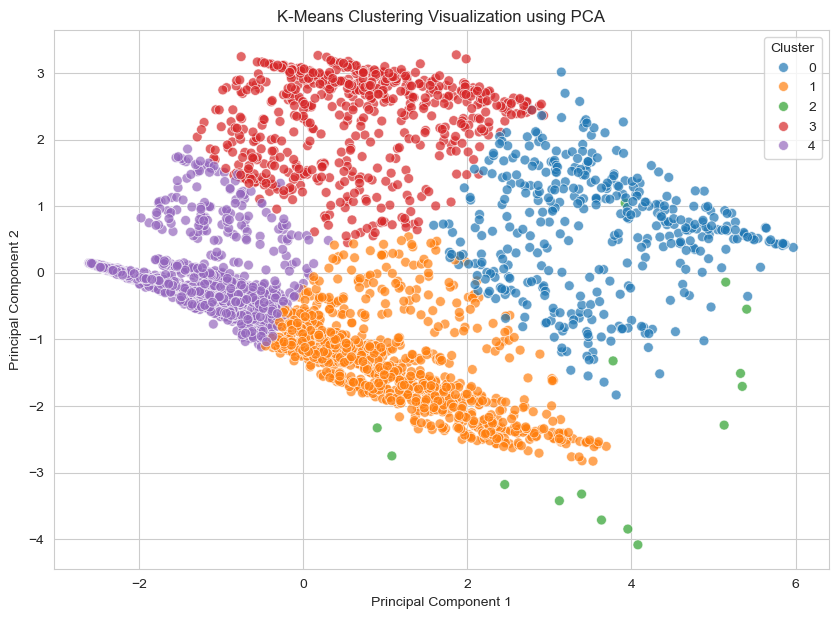

Variance explained by two components: 51.94 %


In [24]:
# Apply PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create visualization DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = kmeans_labels

# Plot clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=50,
    alpha=0.7
)

plt.title("K-Means Clustering Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Step 12: Analyze K-Means clusters

12.1 Count customers in each cluster

In [25]:
cluster_counts = df["KMeans_Cluster"].value_counts().sort_index()

print("Number of customers in each cluster:")
display(cluster_counts.to_frame("Customer Count"))

Number of customers in each cluster:


,Customer Count
KMeans_Cluster,
0,397
1,1066
2,15
3,616
4,1905


12.2 Calculate cluster profiles

In [26]:
# Add cluster labels to original feature data
profile_df = X_imputed.copy()
profile_df["Cluster"] = kmeans_labels

# Calculate average values for each cluster
cluster_profiles = profile_df.groupby("Cluster").mean()

print("K-Means Cluster Profiles:")
display(cluster_profiles.round(2))

K-Means Cluster Profiles:


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Cluster,,,,,,,,,,,
0,172754.71,306.34,4.03,1.02,1.00,54834.38,25.83,1944.58,5.71,5049.99,0.81
1,97354.57,109.39,3.46,1.00,1.00,31892.70,16.74,25.65,0.11,4750.08,0.52
2,138061.40,78.80,3.47,1.00,4.07,93927.87,28.07,506.67,1.60,4613.87,0.53
3,90898.98,322.68,1.21,1.02,1.00,7878.26,10.52,1630.13,4.77,4126.30,0.51
4,33545.11,72.51,1.13,1.02,1.00,3429.63,5.98,15.04,0.08,3564.66,0.15


12.3 Calculate award redemption percentage

In [27]:
award_profile = (
    profile_df.groupby("Cluster")["Award?"]
    .mean()
    .mul(100)
    .round(2)
)

print("Award Redemption Percentage:")
display(award_profile.to_frame("Award Redemption (%)"))

Award Redemption Percentage:


,Award Redemption (%)
Cluster,
0,80.60
1,51.97
2,53.33
3,51.30
4,14.86


12.4 Visualize cluster sizes

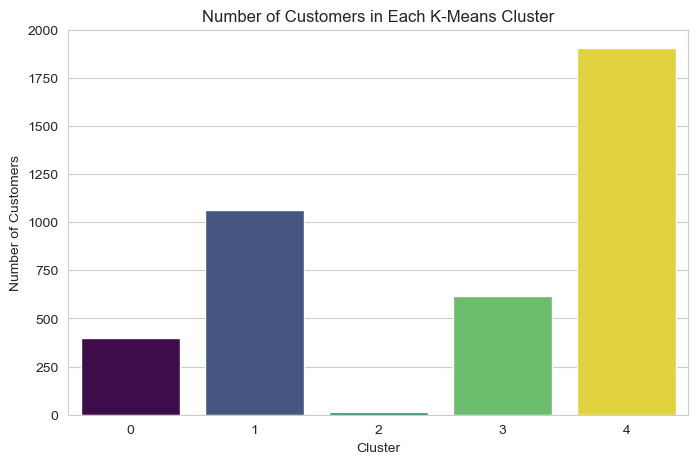

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="KMeans_Cluster",
    hue="KMeans_Cluster",
    palette="viridis",
    legend=False
)

plt.title("Number of Customers in Each K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

Step 13: Hierarchical Clustering

13.1 Create a dendrogram

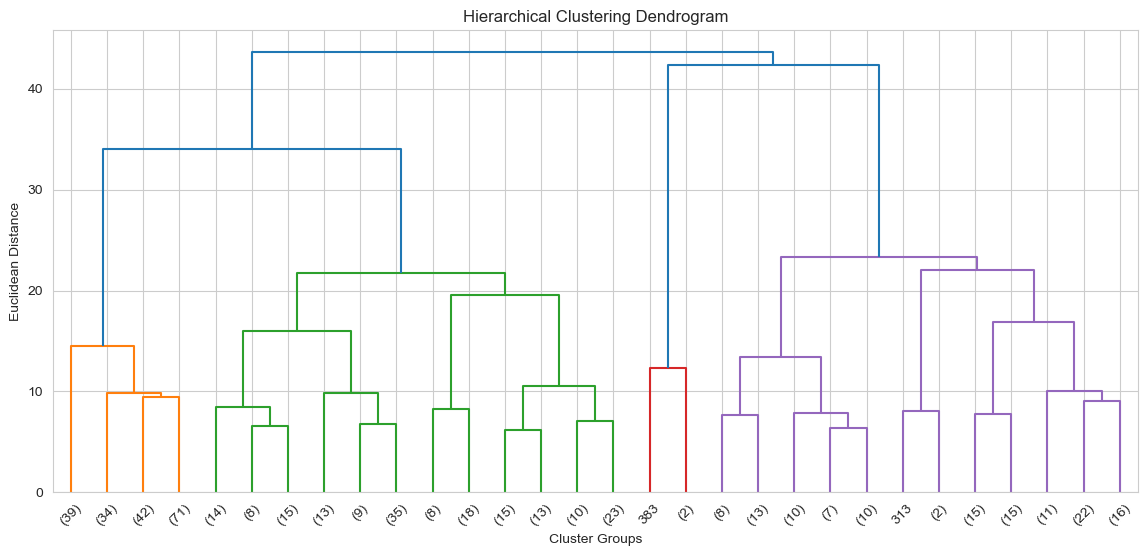

In [29]:
# Take a sample of up to 500 records
sample_size = min(500, len(X_scaled))

rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_scaled[sample_indices]

# Generate hierarchical linkage
linked = linkage(
    X_sample,
    method="ward"
)

# Plot dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster Groups")
plt.ylabel("Euclidean Distance")
plt.show()

13.2 Apply Agglomerative Clustering

In [30]:
hierarchical_results = []

for k in range(2, 7):

    for method in ["ward", "complete", "average"]:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method
        )

        labels = model.fit_predict(X_scaled)

        sil = silhouette_score(X_scaled, labels)
        db = davies_bouldin_score(X_scaled, labels)
        ch = calinski_harabasz_score(X_scaled, labels)

        hierarchical_results.append({
            "Algorithm": "Hierarchical",
            "Clusters": k,
            "Linkage": method,
            "Silhouette Score": sil,
            "Davies-Bouldin Score": db,
            "Calinski-Harabasz Score": ch
        })

hierarchical_results_df = pd.DataFrame(hierarchical_results)

display(
    hierarchical_results_df.sort_values(
        by="Silhouette Score",
        ascending=False
    ).round(4)
)

,Algorithm,Clusters,Linkage,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
1,Hierarchical,2,complete,0.7669,0.4512,424.0314
2,Hierarchical,2,average,0.7669,0.4512,424.0314
4,Hierarchical,3,complete,0.6270,0.6366,455.6131
5,Hierarchical,3,average,0.6270,0.6366,455.6131
7,Hierarchical,4,complete,0.6263,0.7666,312.7377
8,Hierarchical,4,average,0.6263,0.7666,312.7377
10,Hierarchical,5,complete,0.5253,0.7576,251.9092
11,Hierarchical,5,average,0.5253,0.7576,251.9092
14,Hierarchical,6,average,0.4260,0.7946,204.2689
13,Hierarchical,6,complete,0.3057,1.0038,559.3485


13.3 Train the final Hierarchical model

In [31]:
# Set number of clusters
hierarchical_k = 5

# Create model
hierarchical_model = AgglomerativeClustering(
    n_clusters=hierarchical_k,
    linkage="ward"
)

# Fit model and generate labels
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

# Add labels to dataset
df["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed.")

Hierarchical clustering completed.


13.4 Visualize Hierarchical clusters using PCA

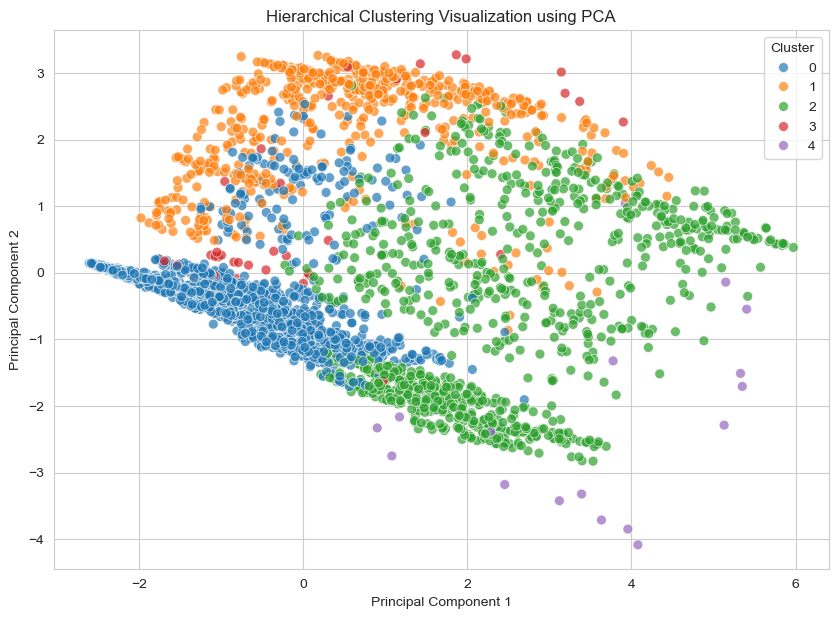

In [32]:
hierarchical_pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

hierarchical_pca_df["Cluster"] = hierarchical_labels

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=hierarchical_pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=50,
    alpha=0.7
)

plt.title("Hierarchical Clustering Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

13.5 Analyze Hierarchical clusters

In [33]:
hierarchical_profile_df = X_imputed.copy()
hierarchical_profile_df["Cluster"] = hierarchical_labels

hierarchical_profiles = (
    hierarchical_profile_df.groupby("Cluster").mean()
)

print("Hierarchical Cluster Profiles:")
display(hierarchical_profiles.round(2))

print("Hierarchical Cluster Sizes:")
display(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
    .to_frame("Customer Count")
)

Hierarchical Cluster Profiles:


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Cluster,,,,,,,,,,,
0,45574.64,93.46,1.44,1.00,1.00,6295.28,7.88,17.90,0.08,3768.27,0.26
1,94562.15,347.90,1.25,1.00,1.00,8008.78,10.53,1725.18,4.98,4187.29,0.43
2,125006.65,145.96,3.99,1.00,1.00,46528.98,20.32,721.12,2.18,4886.29,0.59
3,68876.58,23.26,1.14,2.35,1.00,14689.84,17.53,582.63,2.21,3968.93,0.40
4,129951.39,65.67,3.39,1.00,3.72,86259.89,26.22,422.22,1.33,4488.78,0.50


Hierarchical Cluster Sizes:


,Customer Count
0,2328
1,602
2,1008
3,43
4,18


Step 14: DBSCAN Clustering

14.1 Find a suitable epsilon using the k-distance graph

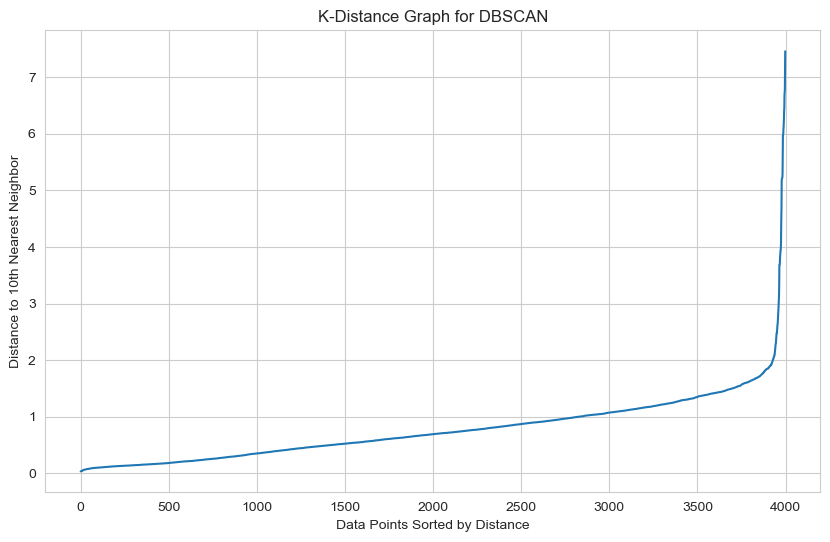

In [34]:
# Set min_samples
min_samples = 10

# Find nearest neighbors
neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X_scaled)

# Calculate distances
distances, indices = neighbors.kneighbors(X_scaled)

# Sort distances to the kth nearest neighbor
k_distances = np.sort(distances[:, min_samples - 1])

# Plot k-distance graph
plt.figure(figsize=(10, 6))

plt.plot(k_distances)

plt.title("K-Distance Graph for DBSCAN")
plt.xlabel("Data Points Sorted by Distance")
plt.ylabel(f"Distance to {min_samples}th Nearest Neighbor")
plt.grid(True)
plt.show()

14.2 Experiment with different DBSCAN parameters

In [35]:
dbscan_results = []

eps_values = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
min_samples_values = [5, 10, 15, 20]

for eps in eps_values:

    for min_pts in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_pts
        )

        labels = model.fit_predict(X_scaled)

        # Count clusters, excluding noise (-1)
        unique_labels = set(labels)

        n_clusters = len(unique_labels - {-1})

        # Calculate noise percentage
        noise_percentage = (
            np.sum(labels == -1) / len(labels)
        ) * 100

        # Calculate evaluation metrics
        if n_clusters >= 2:

            # Exclude noise points for these metrics
            valid_mask = labels != -1
            valid_labels = labels[valid_mask]
            valid_data = X_scaled[valid_mask]

            sil = silhouette_score(
                valid_data,
                valid_labels
            )

            db_score = davies_bouldin_score(
                valid_data,
                valid_labels
            )

            ch_score = calinski_harabasz_score(
                valid_data,
                valid_labels
            )

        else:
            sil = np.nan
            db_score = np.nan
            ch_score = np.nan

        dbscan_results.append({
            "Algorithm": "DBSCAN",
            "Epsilon": eps,
            "Min Samples": min_pts,
            "Number of Clusters": n_clusters,
            "Noise Percentage": noise_percentage,
            "Silhouette Score": sil,
            "Davies-Bouldin Score": db_score,
            "Calinski-Harabasz Score": ch_score
        })

dbscan_results_df = pd.DataFrame(dbscan_results)

display(
    dbscan_results_df.sort_values(
        by="Silhouette Score",
        ascending=False,
        na_position="last"
    ).round(4)
)

,Algorithm,Epsilon,Min Samples,Number of Clusters,Noise Percentage,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
20,DBSCAN,3.0,5,3,0.6002,0.5237,0.6520,202.8824
21,DBSCAN,3.0,10,3,0.7002,0.5183,0.5913,191.7491
22,DBSCAN,3.0,15,2,1.0003,0.5167,0.6359,123.6262
16,DBSCAN,2.5,5,3,0.8002,0.5152,0.5354,172.1733
17,DBSCAN,2.5,10,2,1.0503,0.5147,0.6023,112.6510
18,DBSCAN,2.5,15,2,1.0753,0.5136,0.5871,106.8494
11,DBSCAN,1.5,20,2,5.2263,0.2573,1.7639,1069.3195
10,DBSCAN,1.5,15,2,3.5759,0.2503,1.8024,1039.5913
9,DBSCAN,1.5,10,3,2.1505,0.2474,1.3772,557.4909
8,DBSCAN,1.5,5,4,1.5504,0.2472,1.1028,449.6281


14.3 Select DBSCAN parameters

In [36]:
valid_dbscan_results = dbscan_results_df.dropna(
    subset=["Silhouette Score"]
)

if valid_dbscan_results.empty:
    print("No DBSCAN parameter combination produced at least two clusters.")
else:

    best_dbscan = valid_dbscan_results.sort_values(
        by="Silhouette Score",
        ascending=False
    ).iloc[0]

    best_eps = best_dbscan["Epsilon"]
    best_min_samples = int(best_dbscan["Min Samples"])

    print("Selected DBSCAN Parameters:")
    print("Epsilon:", best_eps)
    print("Min Samples:", best_min_samples)
    print("Number of Clusters:", best_dbscan["Number of Clusters"])
    print("Noise Percentage:", round(best_dbscan["Noise Percentage"], 2))
    print("Silhouette Score:", round(best_dbscan["Silhouette Score"], 4))

Selected DBSCAN Parameters:
Epsilon: 3.0
Min Samples: 5
Number of Clusters: 3
Noise Percentage: 0.6
Silhouette Score: 0.5237


14.4 Train the final DBSCAN model

In [37]:
if valid_dbscan_results.empty:

    print("DBSCAN did not produce a valid multi-cluster solution.")

else:

    dbscan_final = DBSCAN(
        eps=best_eps,
        min_samples=best_min_samples
    )

    dbscan_labels = dbscan_final.fit_predict(X_scaled)

    # Add labels to dataset
    df["DBSCAN_Cluster"] = dbscan_labels

    print("DBSCAN clustering completed.")

    print("\nCluster labels (-1 represents noise):")
    print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN clustering completed.

Cluster labels (-1 represents noise):
-1      24
 0    3938
 1      11
 2      26
Name: count, dtype: int64


14.5 Visualize DBSCAN clusters using PCA

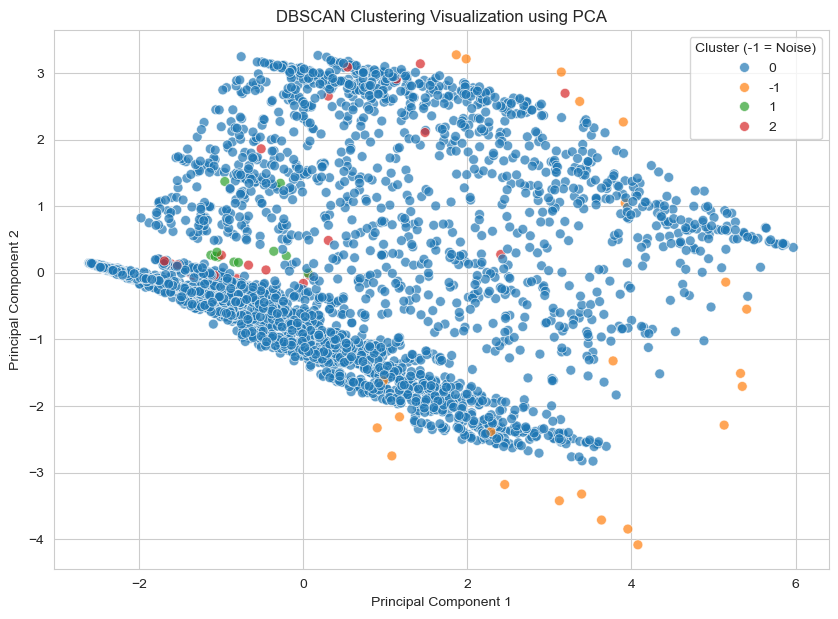

In [38]:
if not valid_dbscan_results.empty:

    dbscan_pca_df = pd.DataFrame(
        X_pca,
        columns=["PC1", "PC2"]
    )

    dbscan_pca_df["Cluster"] = dbscan_labels.astype(str)

    plt.figure(figsize=(10, 7))

    sns.scatterplot(
        data=dbscan_pca_df,
        x="PC1",
        y="PC2",
        hue="Cluster",
        palette="tab10",
        s=50,
        alpha=0.7
    )

    plt.title("DBSCAN Clustering Visualization using PCA")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.legend(title="Cluster (-1 = Noise)")
    plt.show()

14.6 Analyze DBSCAN clusters

In [39]:
if not valid_dbscan_results.empty:

    dbscan_profile_df = X_imputed.copy()
    dbscan_profile_df["Cluster"] = dbscan_labels

    # Exclude noise for the cluster profile
    dbscan_non_noise = dbscan_profile_df[
        dbscan_profile_df["Cluster"] != -1
    ]

    print("DBSCAN Cluster Profiles (excluding noise):")

    display(
        dbscan_non_noise.groupby("Cluster")
        .mean()
        .round(2)
    )

    print("DBSCAN Cluster Sizes:")

    display(
        pd.Series(dbscan_labels)
        .value_counts()
        .sort_index()
        .to_frame("Customer Count")
    )

    print(
        "Noise observations:",
        np.sum(dbscan_labels == -1)
    )

DBSCAN Cluster Profiles (excluding noise):


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Cluster,,,,,,,,,,,
0,73395.35,145.79,2.06,1.0,1.0,16855.74,11.47,458.89,1.36,4118.50,0.37
1,42971.00,0.00,1.00,3.0,1.0,14996.00,14.82,36.36,0.18,4047.64,0.18
2,64442.88,0.00,1.04,2.0,1.0,10244.19,15.88,415.88,1.35,3851.65,0.38


DBSCAN Cluster Sizes:


,Customer Count
-1,24
0,3938
1,11
2,26


Noise observations: 24


Step 15: Compare all clustering algorithms

15.1 Create a comparison table

In [40]:
comparison_results = []

# K-Means
comparison_results.append({
    "Algorithm": "K-Means",
    "Clusters": len(np.unique(kmeans_labels)),
    "Silhouette Score": silhouette_score(X_scaled, kmeans_labels),
    "Davies-Bouldin Score": davies_bouldin_score(X_scaled, kmeans_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_scaled, kmeans_labels)
})

# Hierarchical
comparison_results.append({
    "Algorithm": "Hierarchical",
    "Clusters": len(np.unique(hierarchical_labels)),
    "Silhouette Score": silhouette_score(X_scaled, hierarchical_labels),
    "Davies-Bouldin Score": davies_bouldin_score(X_scaled, hierarchical_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_scaled, hierarchical_labels)
})

# DBSCAN
if not valid_dbscan_results.empty:

    valid_mask = dbscan_labels != -1
    non_noise_labels = dbscan_labels[valid_mask]
    non_noise_data = X_scaled[valid_mask]

    n_dbscan_clusters = len(np.unique(non_noise_labels))

    if n_dbscan_clusters >= 2:

        comparison_results.append({
            "Algorithm": "DBSCAN (non-noise)",
            "Clusters": n_dbscan_clusters,
            "Silhouette Score": silhouette_score(
                non_noise_data,
                non_noise_labels
            ),
            "Davies-Bouldin Score": davies_bouldin_score(
                non_noise_data,
                non_noise_labels
            ),
            "Calinski-Harabasz Score": calinski_harabasz_score(
                non_noise_data,
                non_noise_labels
            )
        })

comparison_df = pd.DataFrame(comparison_results)

print("Final Clustering Algorithm Comparison:")

display(comparison_df.round(4))

Final Clustering Algorithm Comparison:


,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,K-Means,5,0.2961,1.1562,1048.3280
1,Hierarchical,5,0.2778,1.0917,949.2506
2,DBSCAN (non-noise),3,0.5237,0.6520,202.8824


15.2 Visualize silhouette score comparison

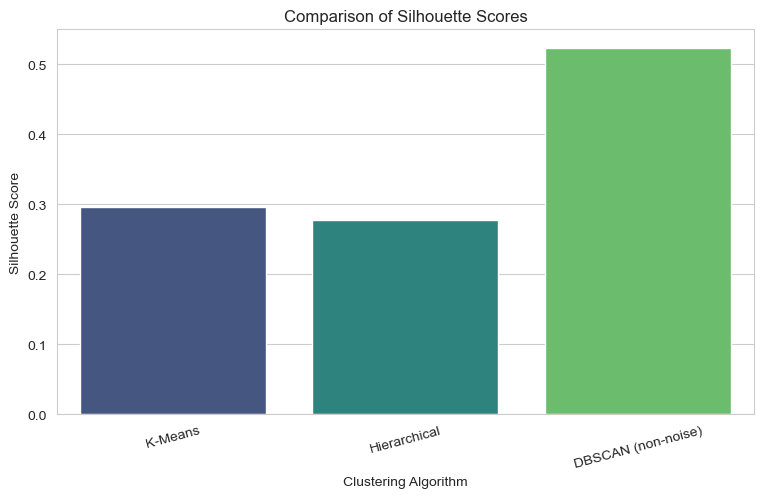

In [41]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x="Algorithm",
    y="Silhouette Score",
    hue="Algorithm",
    palette="viridis",
    legend=False
)

plt.title("Comparison of Silhouette Scores")
plt.xlabel("Clustering Algorithm")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=15)
plt.show()

15.3 Visualize Davies-Bouldin score comparison

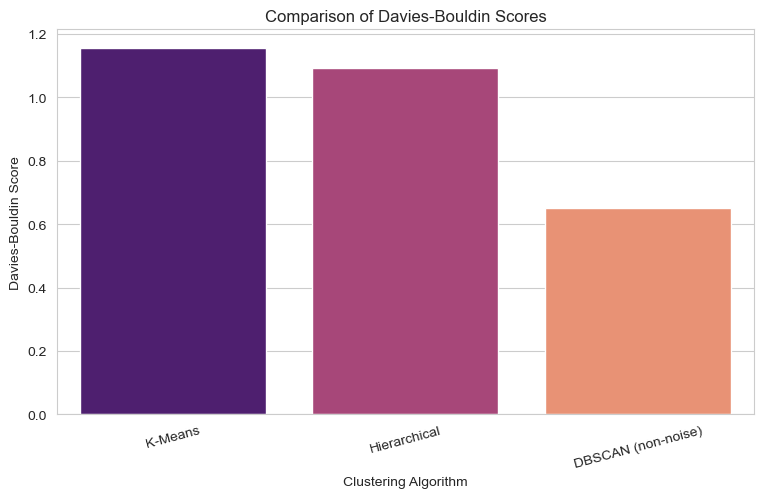

In [42]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x="Algorithm",
    y="Davies-Bouldin Score",
    hue="Algorithm",
    palette="magma",
    legend=False
)

plt.title("Comparison of Davies-Bouldin Scores")
plt.xlabel("Clustering Algorithm")
plt.ylabel("Davies-Bouldin Score")
plt.xticks(rotation=15)
plt.show()

15.4 Visualize Calinski-Harabasz score comparison

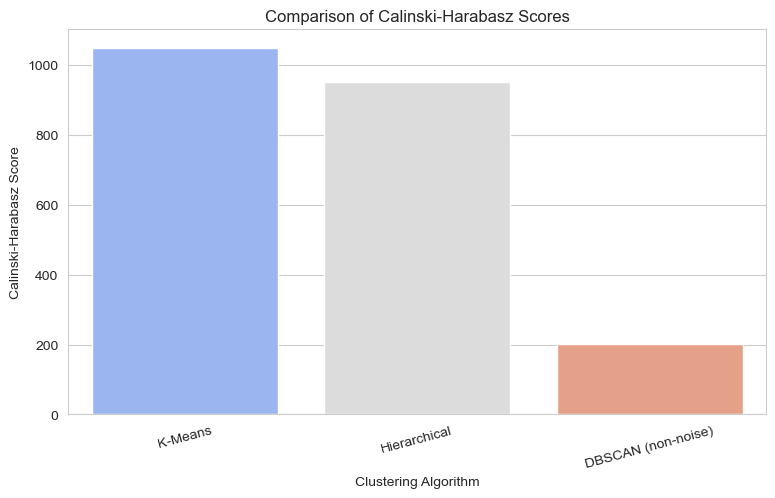

In [43]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x="Algorithm",
    y="Calinski-Harabasz Score",
    hue="Algorithm",
    palette="coolwarm",
    legend=False
)

plt.title("Comparison of Calinski-Harabasz Scores")
plt.xlabel("Clustering Algorithm")
plt.ylabel("Calinski-Harabasz Score")
plt.xticks(rotation=15)
plt.show()

Step 16: Final cluster visualization comparison

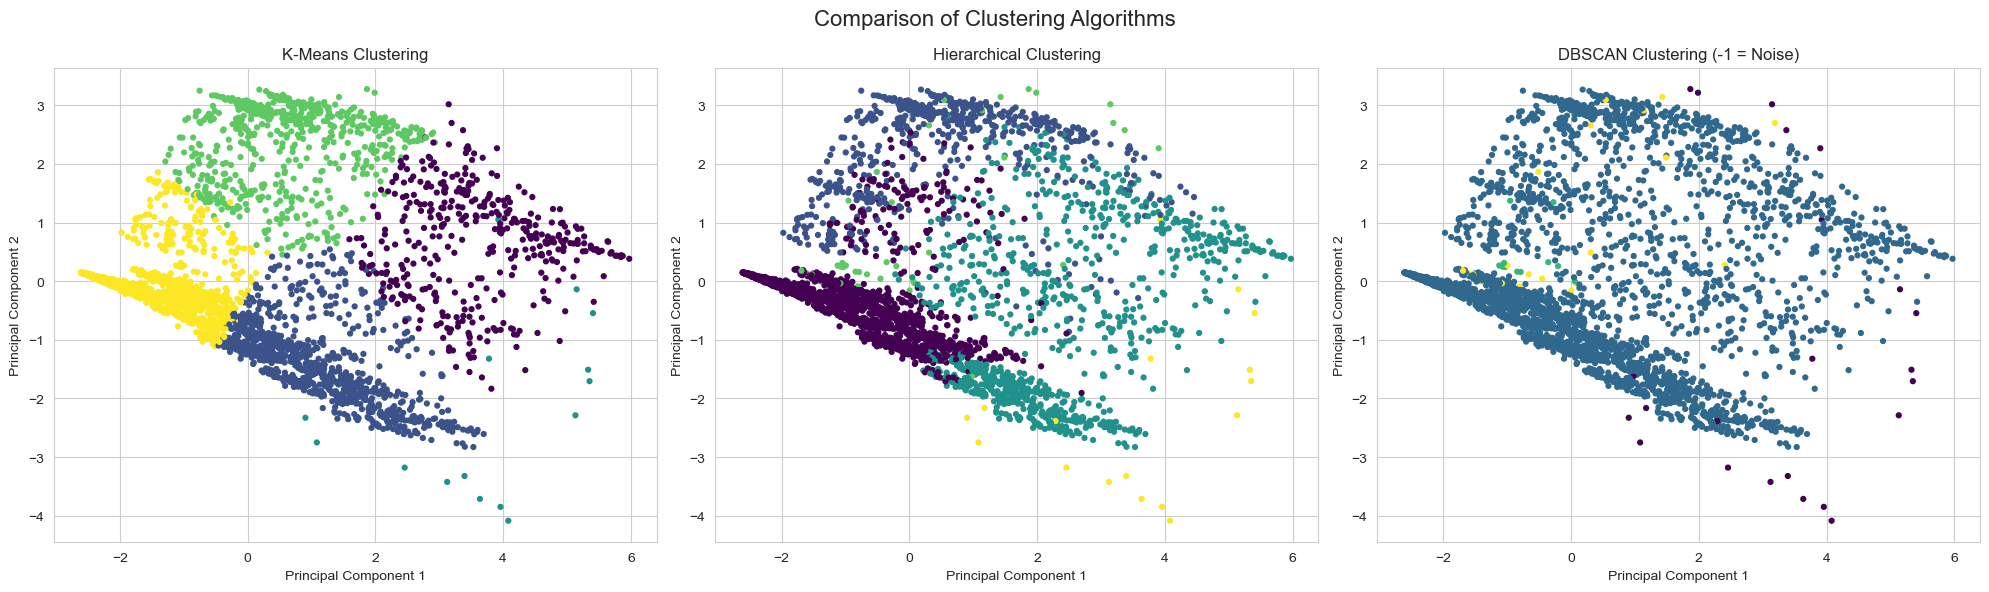

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# K-Means
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=12
)

axes[0].set_title("K-Means Clustering")

# Hierarchical
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=12
)

axes[1].set_title("Hierarchical Clustering")

# DBSCAN
if not valid_dbscan_results.empty:
    axes[2].scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=dbscan_labels,
        cmap="viridis",
        s=12
    )

    axes[2].set_title("DBSCAN Clustering (-1 = Noise)")
else:
    axes[2].set_title("DBSCAN: No valid multi-cluster result")

for ax in axes:
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.suptitle("Comparison of Clustering Algorithms", fontsize=16)
plt.tight_layout()
plt.show()

Step 17: Generate final cluster insights

In [45]:
# K-Means customer counts
print("K-Means Cluster Distribution:")

kmeans_distribution = (
    df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

display(kmeans_distribution.to_frame("Customers"))

# K-Means customer profiles
print("\nK-Means Customer Profiles:")

display(cluster_profiles.round(2))

# Award redemption percentages
print("\nAward Redemption Percentage:")

display(award_profile.to_frame("Award Redemption (%)"))

K-Means Cluster Distribution:


,Customers
KMeans_Cluster,
0,397
1,1066
2,15
3,616
4,1905



K-Means Customer Profiles:


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Cluster,,,,,,,,,,,
0,172754.71,306.34,4.03,1.02,1.00,54834.38,25.83,1944.58,5.71,5049.99,0.81
1,97354.57,109.39,3.46,1.00,1.00,31892.70,16.74,25.65,0.11,4750.08,0.52
2,138061.40,78.80,3.47,1.00,4.07,93927.87,28.07,506.67,1.60,4613.87,0.53
3,90898.98,322.68,1.21,1.02,1.00,7878.26,10.52,1630.13,4.77,4126.30,0.51
4,33545.11,72.51,1.13,1.02,1.00,3429.63,5.98,15.04,0.08,3564.66,0.15



Award Redemption Percentage:


,Award Redemption (%)
Cluster,
0,80.60
1,51.97
2,53.33
3,51.30
4,14.86


Step 18: Save the final output

In [46]:
# Save dataset with cluster labels
df.to_csv(
    "EastWestAirlines_Clustering_Results.csv",
    index=False
)

# Save algorithm comparison
comparison_df.to_csv(
    "Clustering_Algorithm_Comparison.csv",
    index=False
)

# Save K-Means cluster profiles
cluster_profiles.to_csv(
    "KMeans_Cluster_Profiles.csv"
)

print("All output files saved successfully.")

All output files saved successfully.
